In [2]:
# import libraries 

import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 


In [3]:
# load the data set 

df = pd.read_csv('heart.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
# accuring the shape of data set 
df.shape

(918, 12)

In [5]:
# accuring the head of data set 
df.head() 
# display the top 5 element 

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [6]:
df.info()
# give the data sets type , rows , column and all heading(column) data type 


<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [7]:
df.describe() 
# used to generate the summary of the dataset , params like count , rows , column mean median mode , max std deviation

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
df.isnull()
# it returns the data frames in describe and if any nulll value is present it mark it as true or NAN 
df.isnull().sum()
# acts same as the prev.. opr.. df.isnull() , but treats true as 1 and false as 0 , then returns the sum of every columns 

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [9]:
print(df.columns)
# prints the total number of columns its type 

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')


In [10]:
# Check for duplicate rows (returns True/False for each row)
df.duplicated()

# Count the total number of duplicate rows
df.duplicated().sum()

np.int64(0)

In [11]:
# ploting histogram of every data stored in the array initialized 
numeric_columns = ['age' , 'RestingBP' , 'Cholesterol', 'FastingBS', 'MaxHR' , 'Oldpeak' , 'HeartDisease']


<Axes: xlabel='HeartDisease'>

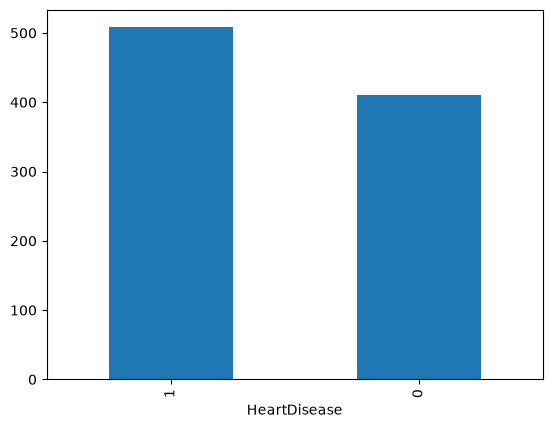

In [12]:
df['HeartDisease'].value_counts().plot(kind = 'bar')

In [13]:
df.isnull().sum() 

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

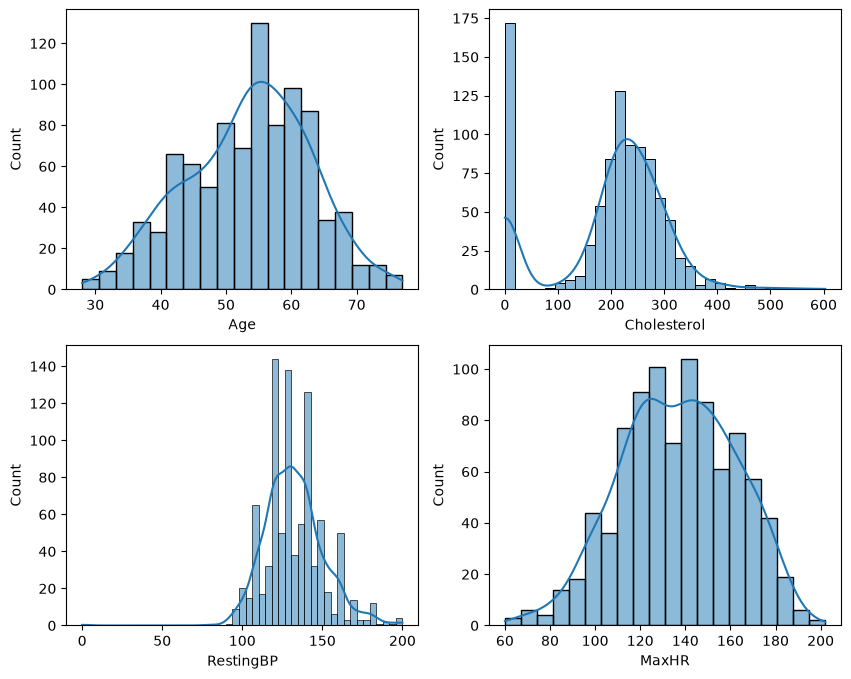

In [14]:
def plotting(var , num):
    plt.subplot(2 ,2 , num)
    sns.histplot(df[var] , kde=True)

plt.figure(figsize=(10, 8))
plt.tight_layout
plotting("Age" , 1)
plotting("Cholesterol" , 2)
plotting("RestingBP" , 3)
plotting("MaxHR" , 4)

In [15]:
# clean the data , removing the impossible part 
# 1stly chrolostrol part
ch_mean = df.loc[df['Cholesterol'] != 0 , 'Cholesterol'].mean()
ch_mean

np.float64(244.6353887399464)

In [16]:
df['Cholesterol'] = df['Cholesterol'].replace(0 , ch_mean)
df['Cholesterol'] = df['Cholesterol'].round(2)

In [17]:
# 2ndly RestingBP part

RestinBP_mean = df.loc[df['RestingBP'] != 0 , 'RestingBP'].mean()
RestinBP_mean

df['RestingBP'] = df['RestingBP'].replace(0 , ch_mean)
df['RestingBP'] = df['RestingBP'].round(2)

In [18]:
# find numerical columns 
num_colms = df.select_dtypes(include=['number']).columns
num_colms

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease'],
      dtype='str')

In [19]:
# find categorical columns 
cate_colms = df.select_dtypes(include=['object' , 'category' , 'string']).columns
cate_colms

Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='str')

<Axes: xlabel='Sex', ylabel='count'>

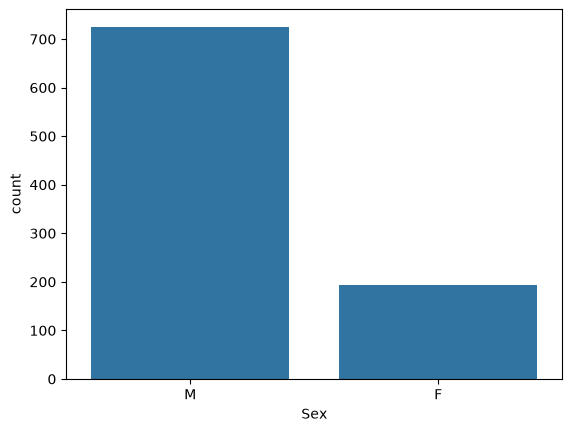

In [20]:
sns.countplot(x=df['Sex'])

<Axes: xlabel='ChestPainType', ylabel='count'>

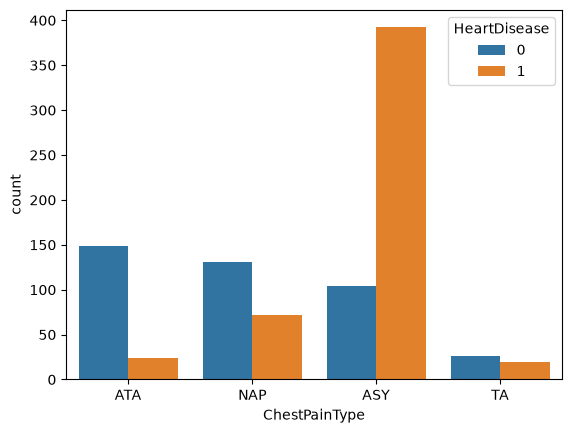

In [21]:
# chest pain type 
# # sns.countplot(x=df['ChestPainType'])
# chest pain hue use type 
sns.countplot(x=df['ChestPainType'] , hue=df['HeartDisease'])
#if 0 no heart disease if 1 heart disesase is present it means if a person have ATA chest pain heart disease chances are high where as if a person have ASY chest pain heart disease chances are very high 


<Axes: xlabel='Sex', ylabel='count'>

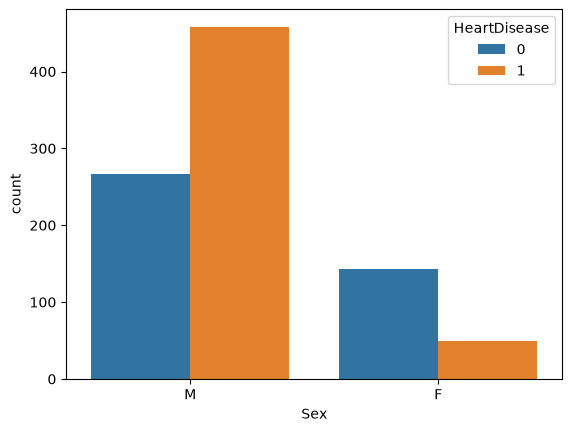

In [22]:
# lly if we want to check the heart disease rate in gender basis we can see as 
sns.countplot(x=df['Sex'] , hue=df['HeartDisease'])
# it expalins that if a patient is male the heart disease is more than that of female 


<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

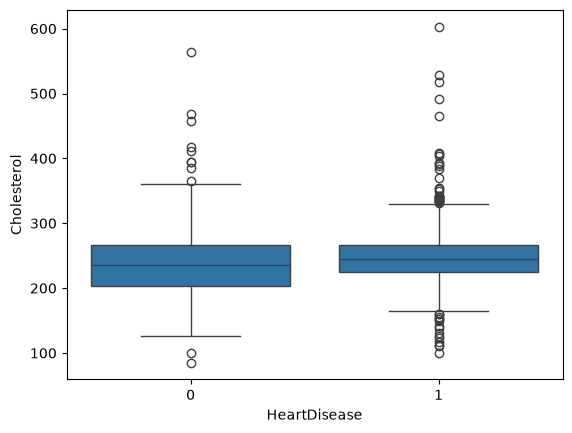

In [23]:
sns.boxplot(x='HeartDisease' , y='Cholesterol' , data=df)

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

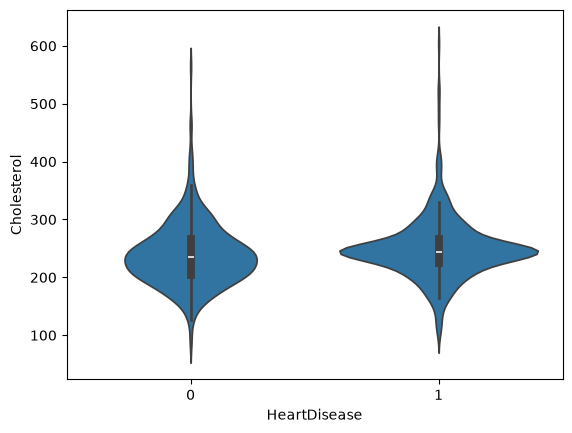

In [24]:
sns.violinplot(x='HeartDisease' , y='Cholesterol' , data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

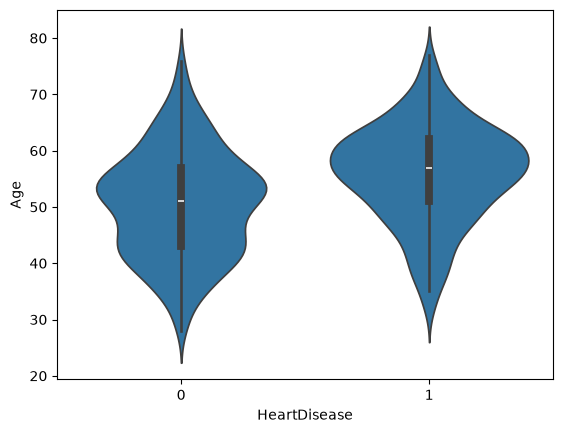

In [25]:
sns.violinplot(x='HeartDisease' , y='Age' , data=df)

<Axes: >

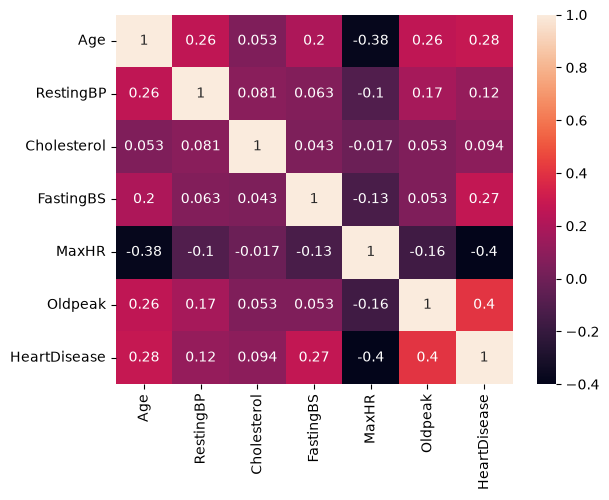

In [26]:
sns.heatmap(df.corr(numeric_only=True) , annot=True)

In [27]:
# data preprocessing and cleaning 

df_encode = pd.get_dummies(df , drop_first=True)
df_encode 
# true and false formate 


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,True,False,False,True,True,False,False,True,False
914,68,144.0,193.0,1,141,3.4,1,True,False,False,False,True,False,False,True,False
915,57,130.0,131.0,0,115,1.2,1,True,False,False,False,True,False,True,True,False
916,57,130.0,236.0,0,174,0.0,1,False,True,False,False,False,False,False,True,False


In [28]:
df_encode = df_encode.astype(int)
df_encode
# converts data in of true false into 0 and 1 

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,1,0,0,1,1,0,0,1,0
914,68,144,193,1,141,3,1,1,0,0,0,1,0,0,1,0
915,57,130,131,0,115,1,1,1,0,0,0,1,0,1,1,0
916,57,130,236,0,174,0,1,0,1,0,0,0,0,0,1,0


In [29]:
# standard scaling 
from sklearn.preprocessing import StandardScaler

In [30]:
# numerical columns 
numerical_col = ['Age' , 'RestingBP' , 'Cholesterol' , 'MaxHR' , 'Oldpeak']

scaler = StandardScaler() 
df_encode[numerical_col] = scaler.fit_transform(df_encode[numerical_col])
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.399826,0.834754,0,1.382928,-0.727592,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.489614,-1.210675,0,0.754157,0.282891,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.145068,0.722161,0,-1.525138,-0.727592,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.290847,-0.572651,0,-1.132156,0.282891,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.944720,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,1,0,0,0,1


In [31]:
df_encode.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    float64
 1   RestingBP          918 non-null    float64
 2   Cholesterol        918 non-null    float64
 3   FastingBS          918 non-null    int64  
 4   MaxHR              918 non-null    float64
 5   Oldpeak            918 non-null    float64
 6   HeartDisease       918 non-null    int64  
 7   Sex_M              918 non-null    int64  
 8   ChestPainType_ATA  918 non-null    int64  
 9   ChestPainType_NAP  918 non-null    int64  
 10  ChestPainType_TA   918 non-null    int64  
 11  RestingECG_Normal  918 non-null    int64  
 12  RestingECG_ST      918 non-null    int64  
 13  ExerciseAngina_Y   918 non-null    int64  
 14  ST_Slope_Flat      918 non-null    int64  
 15  ST_Slope_Up        918 non-null    int64  
dtypes: float64(5), int64(11)
memory usage

In [33]:
# test train split
from sklearn.model_selection import train_test_split

X = df_encode.drop('HeartDisease', axis=1)
y = df_encode['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [36]:
# import models
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        CalibratedClassifierCV(
            SVC(),
            cv=5,
            ensemble=False
        )
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("F1 Score", ascending=False).round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
1                  KNN    0.8859     0.8857  0.9118    0.8986   0.9266
3        Random Forest    0.8750     0.8762  0.9020    0.8889   0.9293
0  Logistic Regression    0.8750     0.8835  0.8922    0.8878   0.9329
4                  SVM    0.8641     0.8598  0.9020    0.8804   0.9417
5    Gradient Boosting    0.8641     0.8812  0.8725    0.8768   0.9081
2        Decision Tree    0.7609     0.8085  0.7451    0.7755   0.7628
